# SmartBlood — Exploratory Data Analysis (Final-Year Project)

**Project:** SmartBlood: An Explainable Machine Learning Framework for Blood Demand Forecasting and Multi-Risk Inventory Decision Support

This notebook performs EDA on the synthetic blood-bank dataset. The analysis is organized to support two project objectives:

1. **Demand forecasting** — understand temporal, blood-group, component, and emergency-related demand patterns.
2. **Inventory decision support** — identify shortage, excess-stock, expiry, and emergency-related risk patterns.

> **Important:** Risk labels in this notebook are baseline analytical proxies for a student project. They are not clinical thresholds and should be replaced with domain-validated rules if real hospital data becomes available.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load Dataset

In [2]:
df = pd.read_csv("../data/raw/smartblood_dataset_2023_2024.csv")
df.head()

,date,blood_group,component,demand,collected,issued,opening_stock,closing_stock,expired,emergency
0,2023-01-01,O+,RBC,60,72,63,149,158,0,2
1,2023-01-01,O+,Platelets,44,41,43,72,69,1,2
2,2023-01-01,O+,Plasma,41,45,36,115,124,0,5
3,2023-01-01,A+,RBC,53,40,50,124,114,0,5
4,2023-01-01,A+,Platelets,40,41,37,52,54,2,4


In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Columns:")
print(df.columns.tolist())

Rows: 17544
Columns: 10
Columns:
['date', 'blood_group', 'component', 'demand', 'collected', 'issued', 'opening_stock', 'closing_stock', 'expired', 'emergency']


## 3. Understand the Dataset

Each row represents daily blood-bank activity for one **date + blood group + blood component** combination.

The main variables are:

- `date` — observation date
- `blood_group` — ABO/Rh blood group
- `component` — RBC, Platelets, or Plasma
- `demand` — blood units requested/demanded
- `collected` — units collected
- `issued` — units issued
- `opening_stock` — stock available at the beginning of the day
- `closing_stock` — stock available at the end of the day
- `expired` — expired units
- `emergency` — emergency requests

In [4]:
df.sample(5, random_state=42)

,date,blood_group,component,demand,collected,issued,opening_stock,closing_stock,expired,emergency
101,2023-01-05,A+,Plasma,32,26,29,95,92,0,2
13758,2024-07-27,B+,RBC,48,39,48,1016,1006,1,2
7864,2023-11-24,A-,Platelets,10,6,10,13,9,0,0
1470,2023-03-03,B+,RBC,43,48,38,348,358,0,2
5863,2023-09-02,B+,Platelets,37,39,37,52,53,1,2


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           17544 non-null  object
 1   blood_group    17544 non-null  object
 2   component      17544 non-null  object
 3   demand         17544 non-null  int64 
 4   collected      17544 non-null  int64 
 5   issued         17544 non-null  int64 
 6   opening_stock  17544 non-null  int64 
 7   closing_stock  17544 non-null  int64 
 8   expired        17544 non-null  int64 
 9   emergency      17544 non-null  int64 
dtypes: int64(7), object(3)
memory usage: 1.3+ MB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
demand,"17,544.00",20.14,16.51,1.00,6.00,14.00,33.00,82.00
collected,"17,544.00",20.37,17.03,0.00,7.00,15.00,33.00,91.00
issued,"17,544.00",19.15,15.76,1.00,6.00,13.00,32.00,85.00
opening_stock,"17,544.00",260.58,328.86,5.00,40.00,133.00,311.00,"1,748.00"
closing_stock,"17,544.00",261.17,329.45,5.00,40.00,134.00,312.25,"1,762.00"
expired,"17,544.00",0.63,0.93,0.00,0.00,0.00,1.00,7.00
emergency,"17,544.00",1.72,2.46,0.00,0.00,1.00,2.00,21.00


## 4. Data Quality Assessment

### 4.1 Missing values

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_percent = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({
    "missing_values": missing,
    "missing_percent": missing_percent
})
missing_report

,missing_values,missing_percent
date,0,0.00
blood_group,0,0.00
component,0,0.00
demand,0,0.00
collected,0,0.00
issued,0,0.00
opening_stock,0,0.00
closing_stock,0,0.00
expired,0,0.00
emergency,0,0.00


### 4.2 Duplicate rows

In [8]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(df.columns.tolist()).head(20))

Duplicate rows: 0


### 4.3 Convert and validate dates

In [9]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Invalid/unparsed dates:", df["date"].isna().sum())
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Unique dates:", df["date"].nunique())

Invalid/unparsed dates: 0
Start date: 2023-01-01 00:00:00
End date: 2024-12-31 00:00:00
Unique dates: 731


### 4.4 Validate categorical values

In [10]:
expected_blood_groups = ["O+", "A+", "B+", "AB+", "O-", "A-", "B-", "AB-"]
expected_components = ["RBC", "Platelets", "Plasma"]

print("Blood groups found:", sorted(df["blood_group"].dropna().unique().tolist()))
print("Unexpected blood groups:", sorted(set(df["blood_group"].dropna().unique()) - set(expected_blood_groups)))
print()
print("Components found:", sorted(df["component"].dropna().unique().tolist()))
print("Unexpected components:", sorted(set(df["component"].dropna().unique()) - set(expected_components)))

Blood groups found: ['A+', 'A-', 'AB+', 'AB-', 'B+', 'B-', 'O+', 'O-']
Unexpected blood groups: []

Components found: ['Plasma', 'Platelets', 'RBC']
Unexpected components: []


In [11]:
print("Blood group counts:")
display(df["blood_group"].value_counts().sort_index())

print("Component counts:")
display(df["component"].value_counts())

Blood group counts:


blood_group
A+     2193
A-     2193
AB+    2193
AB-    2193
B+     2193
B-     2193
O+     2193
O-     2193
Name: count, dtype: int64

Component counts:


component
RBC          5848
Platelets    5848
Plasma       5848
Name: count, dtype: int64

### 4.5 Validate non-negative numeric values

In [12]:
numeric_columns = [
    "demand", "collected", "issued",
    "opening_stock", "closing_stock", "expired", "emergency"
]

negative_report = pd.Series({
    col: int((df[col] < 0).sum())
    for col in numeric_columns
}, name="negative_values")
negative_report

demand           0
collected        0
issued           0
opening_stock    0
closing_stock    0
expired          0
emergency        0
Name: negative_values, dtype: int64

Negative values should **not** be blindly clipped. If negative values appear, inspect the rows and determine whether they are data-entry errors, corrections, or valid domain-specific records. For this synthetic dataset, the expected valid range for these operational counts is non-negative.

### 4.6 Check duplicate business keys

A stronger duplicate check than `df.duplicated()` is to verify whether there is more than one record for the same **date + blood group + component**.

In [13]:
key_columns = ["date", "blood_group", "component"]
key_counts = df.groupby(key_columns).size().reset_index(name="record_count")

print("Duplicate business keys:", (key_counts["record_count"] > 1).sum())
display(key_counts[key_counts["record_count"] > 1].head(20))

Duplicate business keys: 0


,date,blood_group,component,record_count


### 4.7 Check dataset coverage

In [14]:
expected_combinations_per_day = len(expected_blood_groups) * len(expected_components)
records_per_date = df.groupby("date").size()

print("Expected combinations per day:", expected_combinations_per_day)
print("Minimum records per date:", records_per_date.min())
print("Maximum records per date:", records_per_date.max())
print("Dates not having the expected number of records:", (records_per_date != expected_combinations_per_day).sum())

Expected combinations per day: 24
Minimum records per date: 24
Maximum records per date: 24
Dates not having the expected number of records: 0


## 5. Date Feature Engineering

In [15]:
df = df.sort_values(["blood_group", "component", "date"]).reset_index(drop=True)

df["day_of_week"] = df["date"].dt.day_name()
df["day_of_week_num"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["year"] = df["date"].dt.year
df["quarter"] = df["date"].dt.quarter
df["is_weekend"] = (df["day_of_week_num"] >= 5).astype(int)

df["blood_product"] = df["blood_group"] + " - " + df["component"]

df.head()

,date,blood_group,component,demand,collected,issued,opening_stock,closing_stock,expired,emergency,day_of_week,day_of_week_num,month,month_name,year,quarter,is_weekend,blood_product
0,2023-01-01,A+,Plasma,32,31,31,102,102,0,1,Sunday,6,1,January,2023,1,1,A+ - Plasma
1,2023-01-02,A+,Plasma,35,38,36,102,104,0,9,Monday,0,1,January,2023,1,0,A+ - Plasma
2,2023-01-03,A+,Plasma,23,18,23,104,99,0,0,Tuesday,1,1,January,2023,1,0,A+ - Plasma
3,2023-01-04,A+,Plasma,52,48,51,99,95,1,12,Wednesday,2,1,January,2023,1,0,A+ - Plasma
4,2023-01-05,A+,Plasma,32,26,29,95,92,0,2,Thursday,3,1,January,2023,1,0,A+ - Plasma


## 6. Basic Dataset Balance

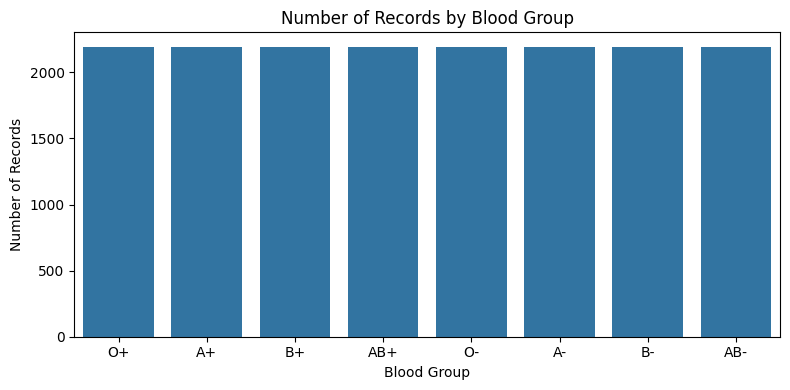

In [16]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="blood_group", order=expected_blood_groups)
plt.title("Number of Records by Blood Group")
plt.xlabel("Blood Group")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

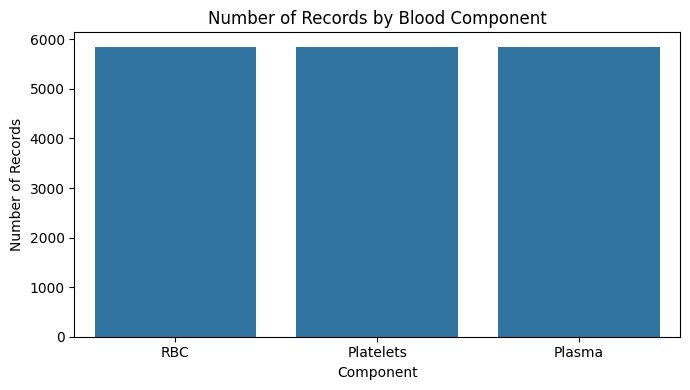

In [17]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="component", order=expected_components)
plt.title("Number of Records by Blood Component")
plt.xlabel("Component")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 7. Univariate Analysis — Demand

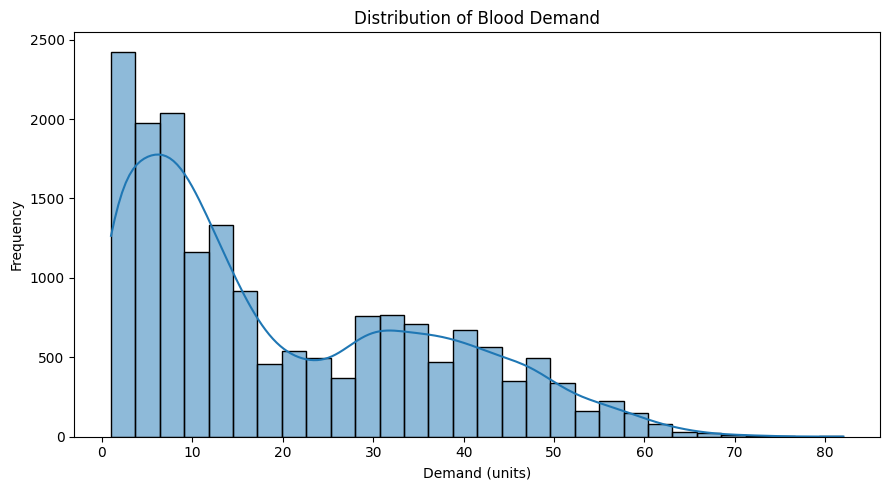

Demand skewness: 0.722
Demand kurtosis: -0.596


In [18]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="demand", bins=30, kde=True)
plt.title("Distribution of Blood Demand")
plt.xlabel("Demand (units)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Demand skewness:", round(df["demand"].skew(), 3))
print("Demand kurtosis:", round(df["demand"].kurtosis(), 3))

## 8. Demand Analysis by Blood Group and Component

In [19]:
demand_by_group = df.groupby("blood_group")["demand"].agg(["sum", "mean", "median", "max"]).reindex(expected_blood_groups)
demand_by_group

,sum,mean,median,max
blood_group,,,,
O+,96709,44.10,43.00,82
A+,82576,37.65,37.00,72
B+,75680,34.51,34.00,67
AB+,33360,15.21,15.00,44
O-,22946,10.46,10.00,34
A-,17567,8.01,7.00,34
B-,15329,6.99,6.00,28
AB-,9217,4.20,3.00,31


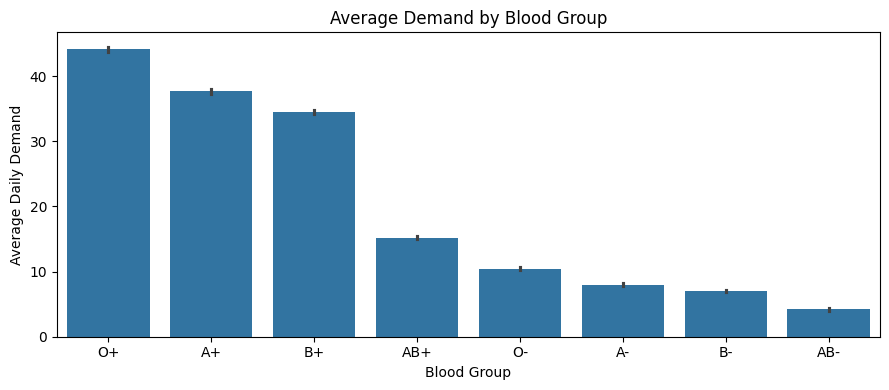

In [20]:
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x="blood_group", y="demand", estimator="mean", order=expected_blood_groups)
plt.title("Average Demand by Blood Group")
plt.xlabel("Blood Group")
plt.ylabel("Average Daily Demand")
plt.tight_layout()
plt.show()

In [21]:
demand_by_component = df.groupby("component")["demand"].agg(["sum", "mean", "median", "max"]).reindex(expected_components)
demand_by_component

,sum,mean,median,max
component,,,,
RBC,145601,24.90,17.00,82
Platelets,113258,19.37,14.00,69
Plasma,94525,16.16,12.00,57


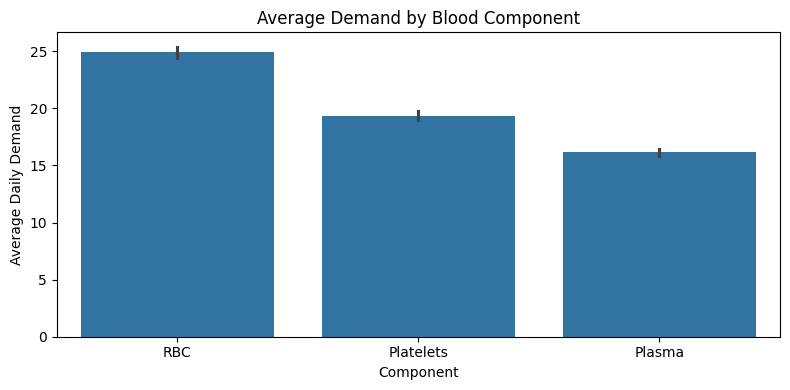

In [22]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="component", y="demand", estimator="mean", order=expected_components)
plt.title("Average Demand by Blood Component")
plt.xlabel("Component")
plt.ylabel("Average Daily Demand")
plt.tight_layout()
plt.show()

In [23]:
product_demand = (
    df.groupby("blood_product")["demand"]
      .agg(["sum", "mean", "median", "max"])
      .sort_values("mean", ascending=False)
)
product_demand

,sum,mean,median,max
blood_product,,,,
O+ - RBC,40145,54.92,55.00,82
A+ - RBC,34329,46.96,47.00,72
B+ - RBC,31571,43.19,43.00,67
O+ - Platelets,31009,42.42,42.00,69
A+ - Platelets,26337,36.03,36.00,61
O+ - Plasma,25555,34.96,34.00,57
B+ - Platelets,24224,33.14,33.00,57
A+ - Plasma,21910,29.97,30.00,54
B+ - Plasma,19885,27.20,27.00,49


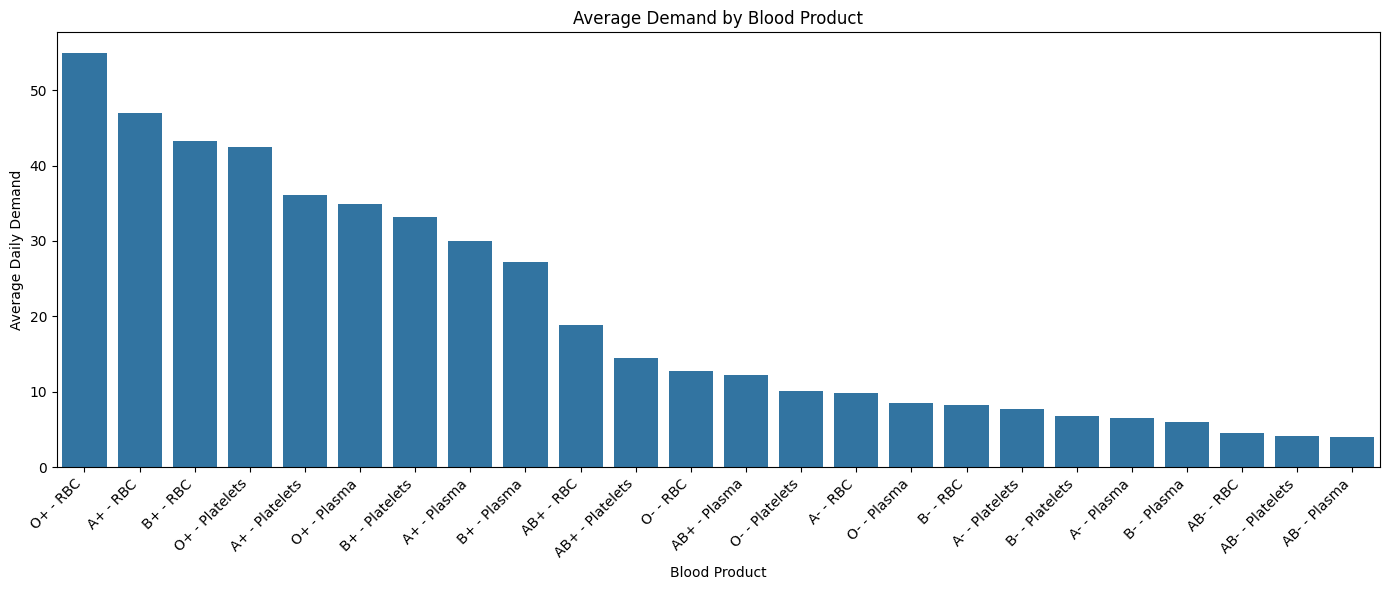

In [24]:
plt.figure(figsize=(14, 6))
product_mean = df.groupby("blood_product")["demand"].mean().sort_values(ascending=False)
sns.barplot(x=product_mean.index, y=product_mean.values)
plt.title("Average Demand by Blood Product")
plt.xlabel("Blood Product")
plt.ylabel("Average Daily Demand")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9. Time-Series Demand Analysis

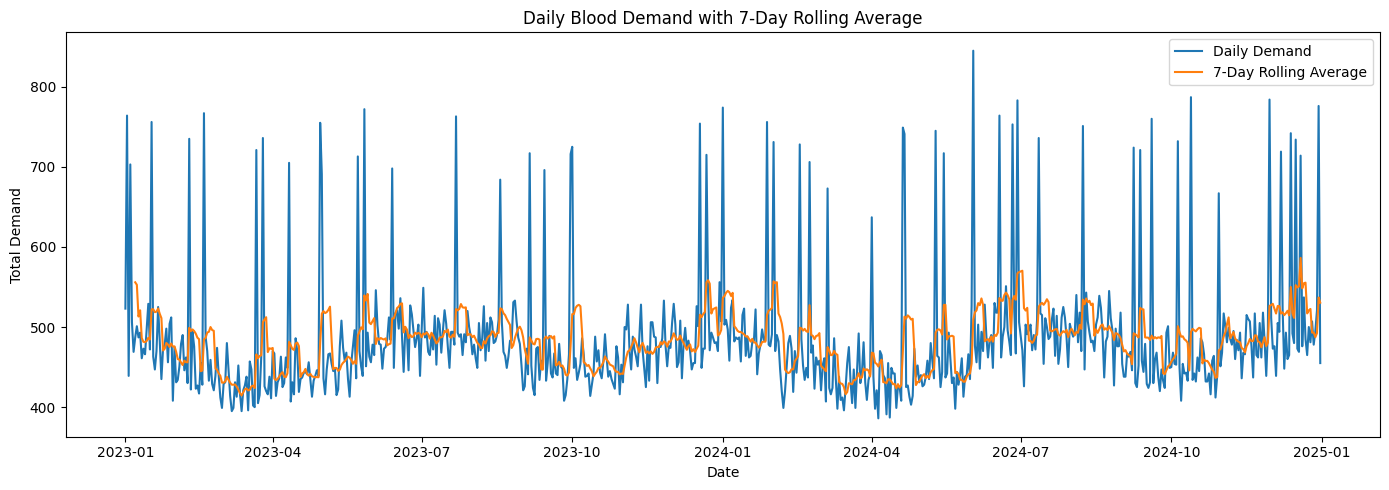

In [25]:
daily_demand = df.groupby("date")["demand"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_demand.index, daily_demand.values, label="Daily Demand")
plt.plot(daily_demand.rolling(7).mean(), label="7-Day Rolling Average")
plt.title("Daily Blood Demand with 7-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total Demand")
plt.legend()
plt.tight_layout()
plt.show()

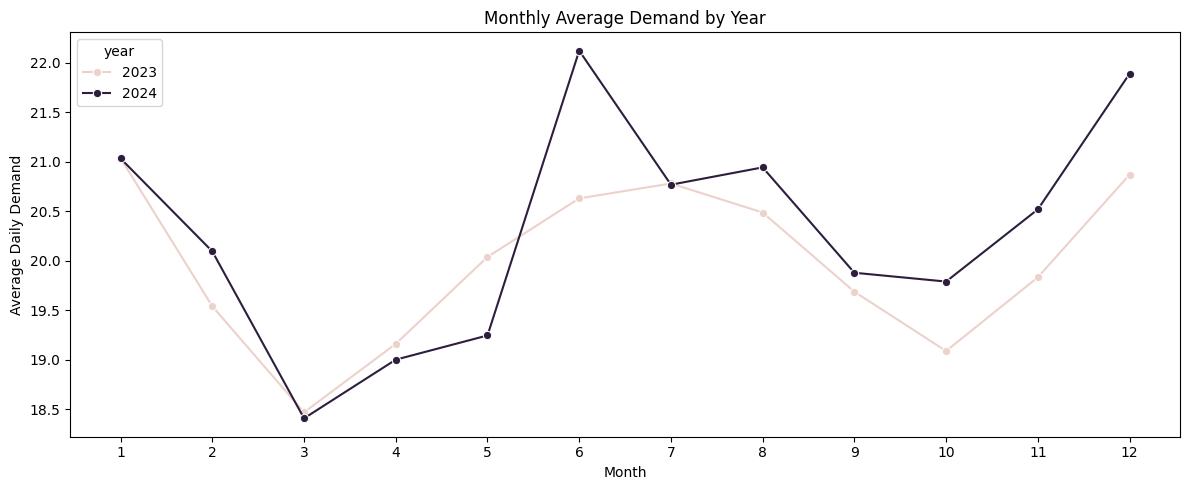

In [26]:
monthly_demand = (
    df.groupby(["year", "month"])["demand"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_demand, x="month", y="demand", hue="year", marker="o")
plt.title("Monthly Average Demand by Year")
plt.xlabel("Month")
plt.ylabel("Average Daily Demand")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [27]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_summary = (
    df.groupby("day_of_week")["demand"]
      .agg(["mean", "median", "max"])
      .reindex(day_order)
)
day_summary

,mean,median,max
day_of_week,,,
Monday,19.77,14.00,75
Tuesday,19.79,14.00,73
Wednesday,19.37,13.00,77
Thursday,19.93,14.00,82
Friday,19.53,14.00,66
Saturday,21.40,15.00,81
Sunday,21.21,15.00,74


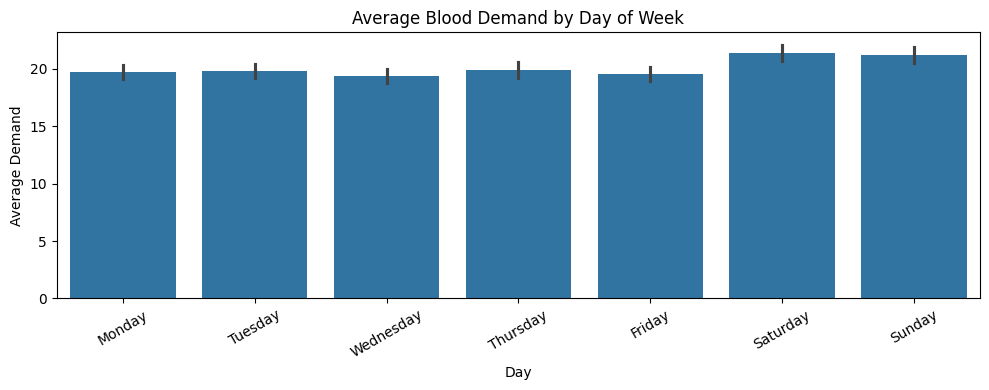

In [28]:
plt.figure(figsize=(10, 4))
sns.barplot(data=df, x="day_of_week", y="demand", order=day_order)
plt.title("Average Blood Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Demand")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 10. Emergency Requests vs Demand

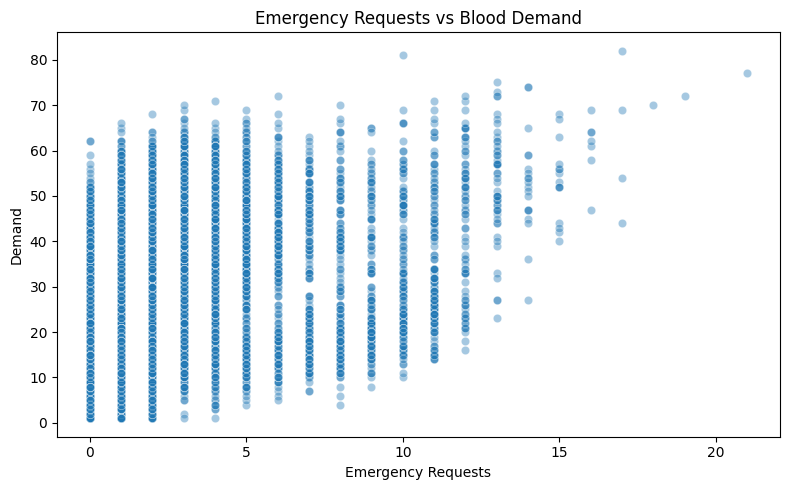

Correlation between emergency requests and demand: 0.544


In [29]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="emergency", y="demand", alpha=0.4)
plt.title("Emergency Requests vs Blood Demand")
plt.xlabel("Emergency Requests")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()

print("Correlation between emergency requests and demand:", round(df["emergency"].corr(df["demand"]), 3))

In [30]:
emergency_summary = (
    df.groupby("emergency")["demand"]
      .agg(["count", "mean", "median", "max"])
)
emergency_summary

,count,mean,median,max
emergency,,,,
0,6989,8.85,7.00,62
1,4155,18.03,13.00,66
2,2356,29.13,30.00,68
3,1450,36.88,37.00,70
4,874,37.61,38.00,71
5,480,37.29,39.00,69
6,246,36.68,39.00,72
7,188,31.94,28.00,63
8,179,30.26,24.00,70


## 11. Inventory Analysis

In [31]:
inventory_summary = df[["opening_stock", "collected", "issued", "expired", "closing_stock"]].describe().T
inventory_summary

,count,mean,std,min,25%,50%,75%,max
opening_stock,"17,544.00",260.58,328.86,5.00,40.00,133.00,311.00,"1,748.00"
collected,"17,544.00",20.37,17.03,0.00,7.00,15.00,33.00,91.00
issued,"17,544.00",19.15,15.76,1.00,6.00,13.00,32.00,85.00
expired,"17,544.00",0.63,0.93,0.00,0.00,0.00,1.00,7.00
closing_stock,"17,544.00",261.17,329.45,5.00,40.00,134.00,312.25,"1,762.00"


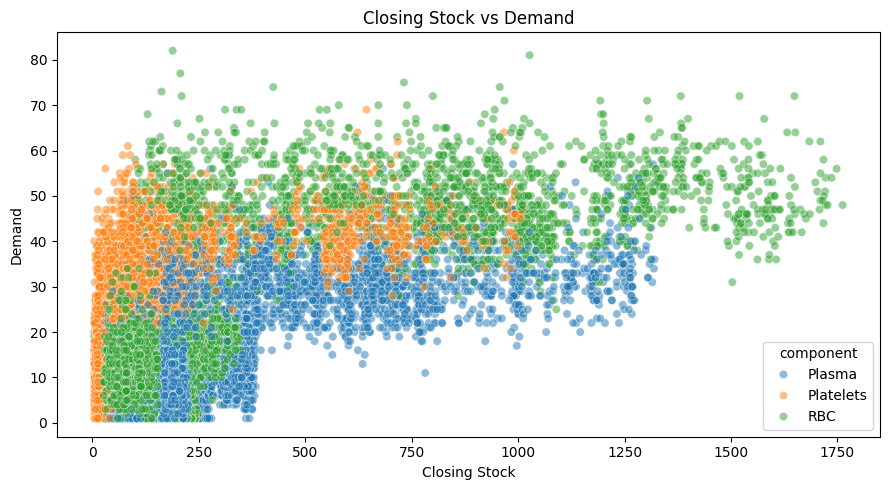

In [32]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="closing_stock", y="demand", hue="component", alpha=0.5)
plt.title("Closing Stock vs Demand")
plt.xlabel("Closing Stock")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()

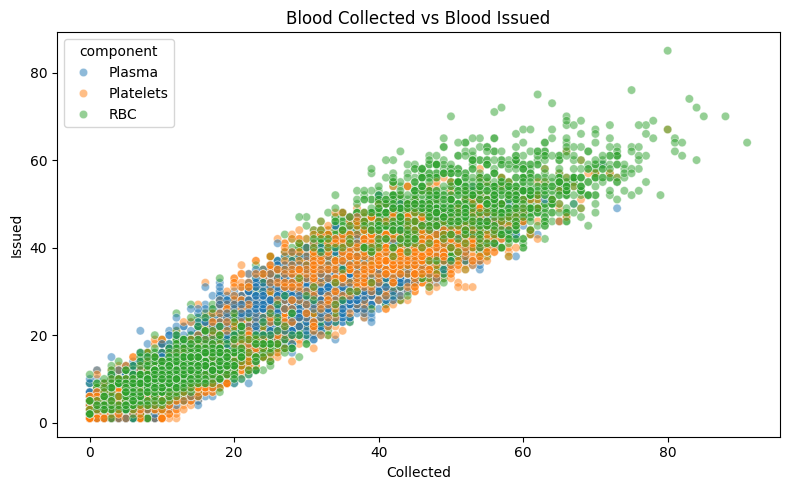

In [33]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="collected", y="issued", hue="component", alpha=0.5)
plt.title("Blood Collected vs Blood Issued")
plt.xlabel("Collected")
plt.ylabel("Issued")
plt.tight_layout()
plt.show()

### 11.1 Inventory consistency check

For a simple daily stock-flow model, an expected closing-stock relationship is:

`closing_stock = opening_stock + collected - issued - expired`

Because the dataset is synthetic, this is treated as a **validation check**, not an assumption that every real blood-bank workflow follows exactly this equation.

In [34]:
df["calculated_closing_stock"] = (
    df["opening_stock"]
    + df["collected"]
    - df["issued"]
    - df["expired"]
)

df["stock_difference"] = df["closing_stock"] - df["calculated_closing_stock"]

print("Rows with stock inconsistency:", (df["stock_difference"] != 0).sum())
print("Maximum absolute difference:", df["stock_difference"].abs().max())

display(df.loc[df["stock_difference"] != 0,
               ["date", "blood_group", "component", "opening_stock", "collected", "issued", "expired", "closing_stock", "calculated_closing_stock", "stock_difference"]].head(20))

Rows with stock inconsistency: 0
Maximum absolute difference: 0


,date,blood_group,component,opening_stock,collected,issued,expired,closing_stock,calculated_closing_stock,stock_difference


## 12. Expiry and Wastage Analysis

In [35]:
expiry_by_group = (
    df.groupby("blood_group")["expired"]
      .agg(["sum", "mean", "max"])
      .reindex(expected_blood_groups)
)
expiry_by_group

,sum,mean,max
blood_group,,,
O+,1606,0.73,7
A+,1493,0.68,5
B+,1557,0.71,5
AB+,1115,0.51,4
O-,1172,0.53,7
A-,1250,0.57,5
B-,1374,0.63,6
AB-,1474,0.67,7


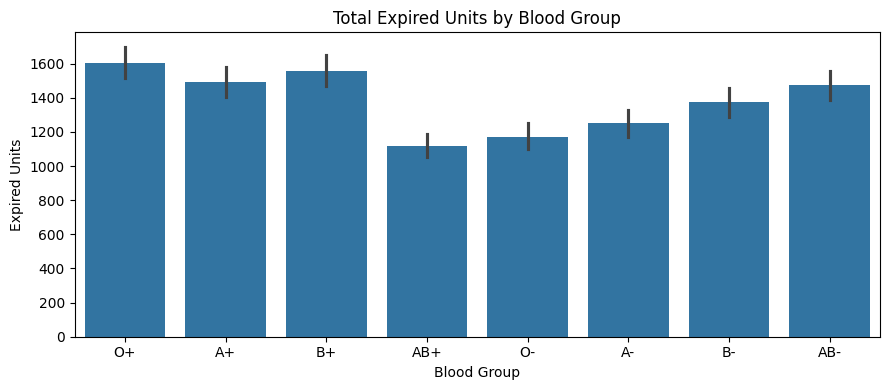

In [36]:
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x="blood_group", y="expired", estimator="sum", order=expected_blood_groups)
plt.title("Total Expired Units by Blood Group")
plt.xlabel("Blood Group")
plt.ylabel("Expired Units")
plt.tight_layout()
plt.show()

In [37]:
expiry_by_component = df.groupby("component")["expired"].agg(["sum", "mean", "max"]).reindex(expected_components)
expiry_by_component

,sum,mean,max
component,,,
RBC,2298,0.39,4
Platelets,7585,1.30,7
Plasma,1158,0.20,3


### Expiry rate

This baseline rate uses available stock flow as the denominator. The `+1` prevents division by zero; it is a technical safeguard rather than a clinical rule.

In [38]:
df["expiry_rate"] = df["expired"] / (df["opening_stock"] + df["collected"] + 1)

print("Mean expiry rate (%):", round(df["expiry_rate"].mean() * 100, 3))
print("Maximum expiry rate (%):", round(df["expiry_rate"].max() * 100, 3))

Mean expiry rate (%): 1.371
Maximum expiry rate (%): 33.333


## 13. Baseline Inventory Risk Indicators

These indicators are designed for the SmartBlood prototype. They should be described in the report as **baseline decision-support heuristics**, not medical standards.

In [39]:
# 1. Operational shortage proxy:
# Closing stock is below same-day demand.
df["shortage_risk"] = (df["closing_stock"] < df["demand"]).astype(int)

# 2. Stock coverage ratio:
# Higher values indicate more stock relative to same-day demand.
df["stock_coverage_ratio"] = df["closing_stock"] / (df["demand"] + 1)

# 3. Baseline excess-stock proxy:
# More than 2x same-day demand is flagged for investigation.
df["excess_stock_risk"] = (df["stock_coverage_ratio"] >= 2).astype(int)

# 4. Expiry-risk proxy:
# Any expiry is treated as an event requiring investigation.
df["expiry_risk"] = (df["expired"] > 0).astype(int)

# 5. Emergency-risk proxy:
# Any emergency request is treated as an emergency event.
df["emergency_risk"] = (df["emergency"] > 0).astype(int)

df[["shortage_risk", "excess_stock_risk", "expiry_risk", "emergency_risk"]].mean().mul(100).round(2)

shortage_risk        5.08
excess_stock_risk   83.09
expiry_risk         40.82
emergency_risk      60.16
dtype: float64

### Risk summary by blood product

In [40]:
risk_summary = (
    df.groupby("blood_product")
      .agg(
          avg_demand=("demand", "mean"),
          avg_closing_stock=("closing_stock", "mean"),
          shortage_rate=("shortage_risk", "mean"),
          excess_stock_rate=("excess_stock_risk", "mean"),
          expiry_event_rate=("expiry_risk", "mean"),
          emergency_event_rate=("emergency_risk", "mean"),
          avg_expiry_rate=("expiry_rate", "mean")
      )
      .sort_values("shortage_rate", ascending=False)
)

risk_summary[["shortage_rate", "excess_stock_rate", "expiry_event_rate", "emergency_event_rate", "avg_expiry_rate"]] *= 100
risk_summary

,avg_demand,avg_closing_stock,shortage_rate,excess_stock_rate,expiry_event_rate,emergency_event_rate,avg_expiry_rate
blood_product,,,,,,,
AB+ - Platelets,14.53,18.04,33.52,15.32,61.83,61.29,2.79
O- - Platelets,10.14,14.86,25.31,25.99,61.42,48.56,3.83
A- - Platelets,7.76,12.39,19.70,34.75,65.66,41.72,5.35
B- - Platelets,6.75,12.15,17.10,41.18,69.22,35.16,6.44
A+ - Platelets,36.03,103.02,9.58,65.39,78.93,90.97,1.17
AB- - Platelets,4.18,11.44,8.62,67.03,75.10,20.11,8.45
A- - RBC,9.76,115.15,2.87,92.07,30.23,39.12,0.37
B+ - Platelets,33.14,121.82,2.87,78.39,79.07,90.56,1.06
B- - RBC,8.25,88.85,0.82,93.16,33.11,36.11,0.52


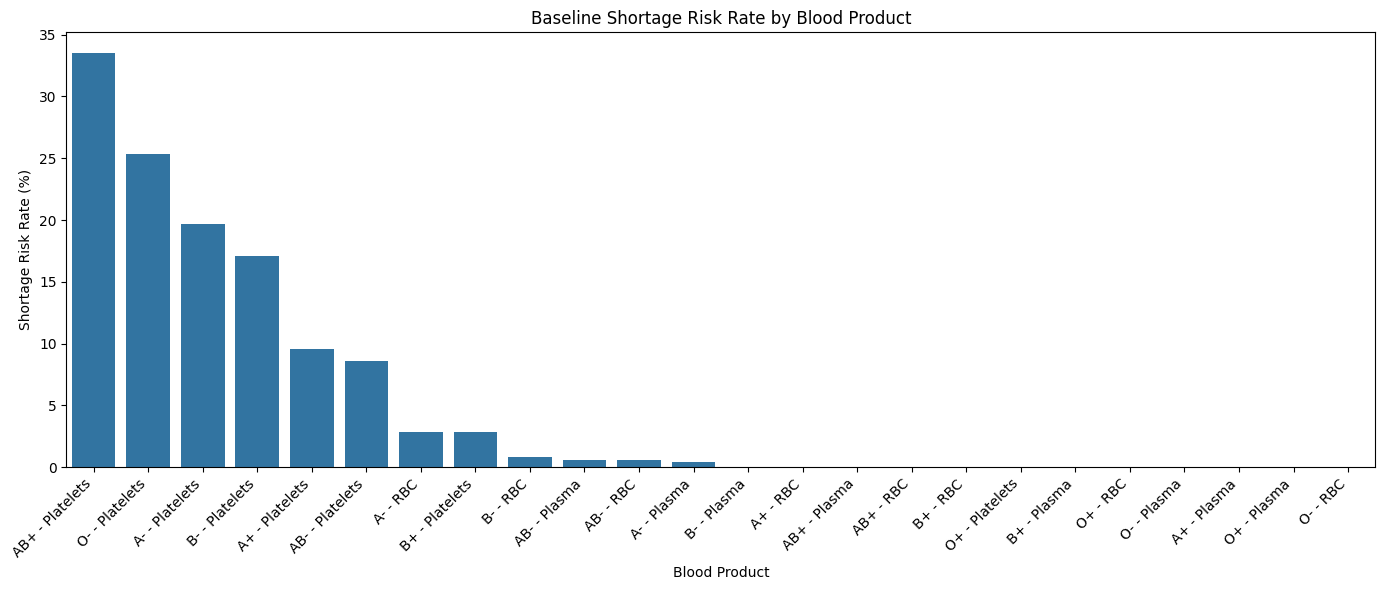

In [41]:
plt.figure(figsize=(14, 6))
shortage_rates = risk_summary["shortage_rate"].sort_values(ascending=False)
sns.barplot(x=shortage_rates.index, y=shortage_rates.values)
plt.title("Baseline Shortage Risk Rate by Blood Product")
plt.xlabel("Blood Product")
plt.ylabel("Shortage Risk Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

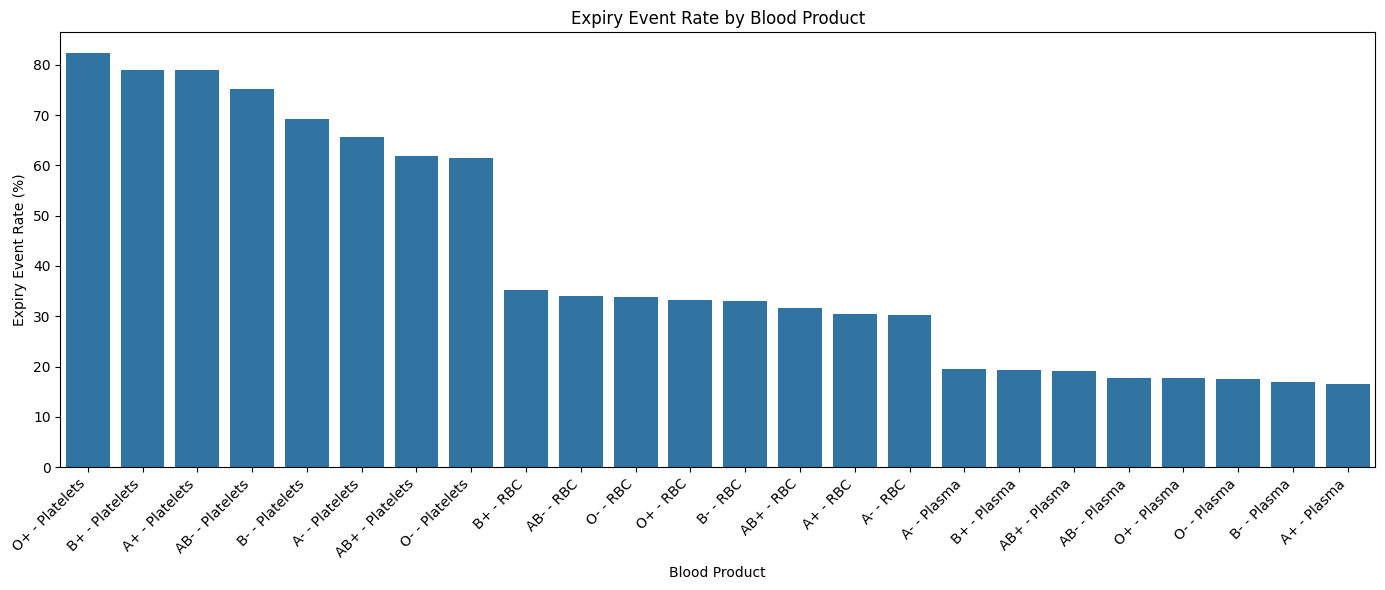

In [42]:
plt.figure(figsize=(14, 6))
expiry_rates = risk_summary["expiry_event_rate"].sort_values(ascending=False)
sns.barplot(x=expiry_rates.index, y=expiry_rates.values)
plt.title("Expiry Event Rate by Blood Product")
plt.xlabel("Blood Product")
plt.ylabel("Expiry Event Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 14. Outlier Analysis

Outliers should **not** be automatically deleted. In blood-bank data, unusually high demand can represent a genuine emergency or an unusual operational event. Therefore, this notebook identifies potential outliers for investigation.

In [43]:
outlier_columns = [
    "demand", "collected", "issued",
    "opening_stock", "closing_stock", "expired", "emergency"
]

outlier_summary = []

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, q1, q3, iqr, lower, upper, int(count)])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["column", "Q1", "Q3", "IQR", "lower_bound", "upper_bound", "outlier_count"]
)
outlier_summary

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
0,demand,6.00,33.00,27.00,-34.50,73.50,6
1,collected,7.00,33.00,26.00,-32.00,72.00,51
2,issued,6.00,32.00,26.00,-33.00,71.00,7
3,opening_stock,40.00,311.00,271.00,-366.50,717.50,2007
4,closing_stock,40.00,312.25,272.25,-368.38,720.62,1994
5,expired,0.00,1.00,1.00,-1.50,2.50,928
6,emergency,0.00,2.00,2.00,-3.00,5.00,1240


### Outliers by blood product

A global IQR can incorrectly flag normal values from one blood product as unusual. For forecasting, inspect the distribution within each **blood group + component**.

In [44]:
def iqr_outliers(group, column="demand"):
    q1 = group[column].quantile(0.25)
    q3 = group[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return group[(group[column] < lower) | (group[column] > upper)]

product_outliers = []
for product, group in df.groupby("blood_product"):
    temp = iqr_outliers(group, "demand").copy()
    if not temp.empty:
        temp["blood_product"] = product
        product_outliers.append(temp)

if product_outliers:
    product_outliers = pd.concat(product_outliers, ignore_index=True)
    display(product_outliers[
        ["date", "blood_group", "component", "demand", "emergency", "closing_stock", "blood_product"]
    ].sort_values("demand", ascending=False).head(30))
else:
    print("No demand outliers detected within blood products.")

,date,blood_group,component,demand,emergency,closing_stock,blood_product
416,2023-02-09,O+,RBC,82,17,189,O+ - RBC
421,2024-06-29,O+,RBC,81,10,1027,O+ - RBC
417,2023-03-22,O+,RBC,77,21,207,O+ - RBC
419,2023-12-18,O+,RBC,75,13,732,O+ - RBC
418,2023-07-22,O+,RBC,74,14,425,O+ - RBC
420,2024-06-02,O+,RBC,74,14,957,O+ - RBC
415,2023-01-17,O+,RBC,73,13,163,O+ - RBC
50,2024-11-30,A+,RBC,72,13,1649,A+ - RBC
31,2023-02-18,A+,RBC,72,19,210,A+ - RBC
33,2023-04-30,A+,RBC,69,16,339,A+ - RBC


## 15. Feature Availability and Data Leakage Check

For a forecasting model, a feature must be available **before or at the prediction time**. Same-day or future values can leak information about the target.

For example, if the goal is to predict tomorrow's demand, tomorrow's `issued`, `expired`, or `closing_stock` must not be used as direct inputs. Historical versions can be used through lag features.

In [45]:
# Create historical lag features for later ML work.
# These are based on the previous observations for each blood product.
df["demand_lag_1"] = df.groupby(["blood_group", "component"])["demand"].shift(1)
df["demand_lag_7"] = df.groupby(["blood_group", "component"])["demand"].shift(7)
df["demand_rolling_7"] = (
    df.groupby(["blood_group", "component"])["demand"]
      .transform(lambda s: s.shift(1).rolling(7).mean())
)

df[["date", "blood_group", "component", "demand", "demand_lag_1", "demand_lag_7", "demand_rolling_7"]].head(15)

,date,blood_group,component,demand,demand_lag_1,demand_lag_7,demand_rolling_7
0,2023-01-01,A+,Plasma,32,NaN,NaN,NaN
1,2023-01-02,A+,Plasma,35,32.00,NaN,NaN
2,2023-01-03,A+,Plasma,23,35.00,NaN,NaN
3,2023-01-04,A+,Plasma,52,23.00,NaN,NaN
4,2023-01-05,A+,Plasma,32,52.00,NaN,NaN
5,2023-01-06,A+,Plasma,30,32.00,NaN,NaN
6,2023-01-07,A+,Plasma,36,30.00,NaN,NaN
7,2023-01-08,A+,Plasma,31,36.00,32.00,34.29
8,2023-01-09,A+,Plasma,29,31.00,35.00,34.14
9,2023-01-10,A+,Plasma,32,29.00,23.00,33.29


## 16. Correlation Analysis

Correlation is useful for understanding linear relationships, but it does not prove causation. For forecasting, leakage and feature availability should be considered before selecting features.

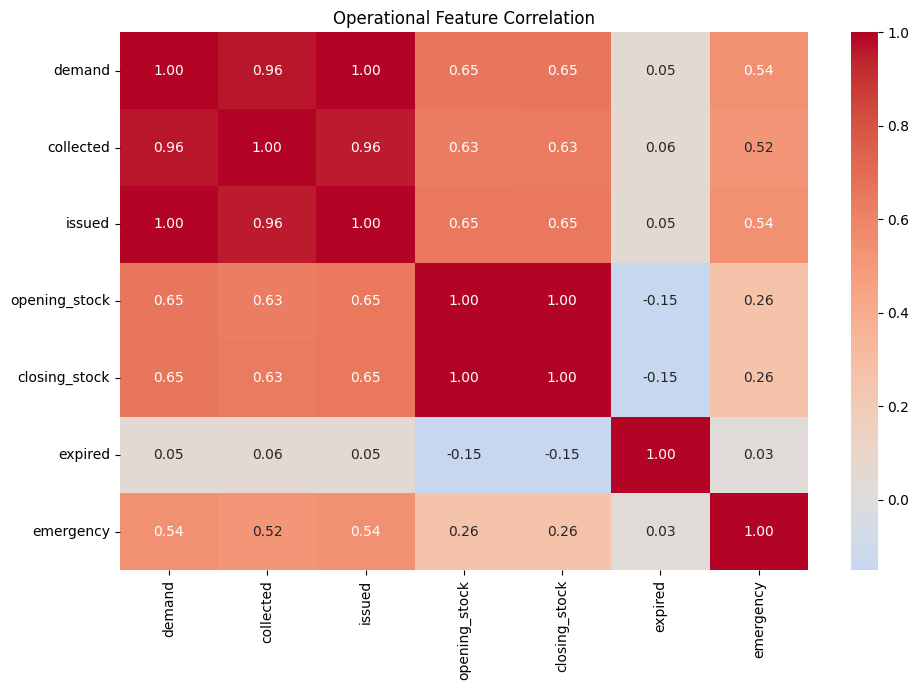

In [46]:
correlation_columns = [
    "demand", "collected", "issued",
    "opening_stock", "closing_stock", "expired", "emergency"
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[correlation_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Operational Feature Correlation")
plt.tight_layout()
plt.show()

## 17. Final Data Quality Summary

In [49]:
quality_summary = pd.DataFrame({
    "Check": [
        "Rows",
        "Columns",
        "Missing values",
        "Duplicate rows",
        "Invalid dates",
        "Negative numeric values",
        "Duplicate business keys",
        "Unexpected blood groups",
        "Unexpected components",
        "Dates with incomplete product coverage",
        "Stock-flow inconsistencies"
    ],
    "Result": [
        len(df),
        len(df.columns),
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        int(df["date"].isna().sum()),
        int(sum((df[col] < 0).sum() for col in numeric_columns)),
        int((key_counts["record_count"] > 1).sum()),
        len(set(df["blood_group"].dropna().unique()) - set(expected_blood_groups)),
        len(set(df["component"].dropna().unique()) - set(expected_components)),
        int((records_per_date != expected_combinations_per_day).sum()),
        int((df["stock_difference"] != 0).sum())
    ]
})
quality_summary

,Check,Result
0,Rows,17544
1,Columns,29
2,Missing values,360
3,Duplicate rows,0
4,Invalid dates,0
5,Negative numeric values,0
6,Duplicate business keys,0
7,Unexpected blood groups,0
8,Unexpected components,0
9,Dates with incomplete product coverage,0


## 18. Key EDA Findings

Use the cells above to obtain the exact numerical findings for the current dataset. The final report should discuss findings under these themes:

1. **Dataset quality:** missing values, duplicates, invalid categories, date coverage, and stock-flow consistency.
2. **Demand patterns:** differences between blood groups/components and variation over time.
3. **Temporal behavior:** daily fluctuations, rolling trends, monthly patterns, and weekday effects.
4. **Emergency behavior:** whether emergency requests are associated with higher demand and whether emergency events correspond to demand spikes.
5. **Inventory behavior:** relationship between stock, collection, issue, and demand.
6. **Expiry/wastage:** which blood products show more expiry events or higher expiry rates.
7. **Risk behavior:** which blood products have higher baseline shortage, excess-stock, expiry, or emergency-event rates.
8. **Outliers:** unusual values should be investigated and retained when they represent genuine operational events.
9. **Forecasting readiness:** historical lag and rolling features are more appropriate for future-demand prediction than future operational values.

## 19. Save Cleaned/Engineered Dataset

The original raw dataset is not overwritten. The processed version is saved separately for the next stages of the SmartBlood ML pipeline.

In [50]:
processed_path = "../data/processed/smartblood_dataset_2023_2024_eda_ready.csv"
df.to_csv(processed_path, index=False)
print(f"Saved processed dataset to: {processed_path}")

Saved processed dataset to: ../data/processed/smartblood_dataset_2023_2024_eda_ready.csv


## 20. Recommended Next Step

After completing this EDA, move to a separate notebook:

`02_Feature_Engineering.ipynb`

Recommended pipeline:

**EDA → Feature Engineering → Time-Based Train/Test Split → Baseline Model → ML Forecasting → Model Evaluation → SHAP Explainability → Risk Decision Layer → Hospital Management Dashboard**

Do not train the final model on the entire dataset before evaluation. For forecasting, use a **chronological/time-based split** rather than a random train-test split.